# 02 · Clusterização dos países pelo método DTW

Agrupa os países pela **forma da trajetória** de quatro indicadores (`TFR`, `LEx`, `IMR`, `MedianAgePop`) entre 1950 e 2023, usando *Dynamic Time Warping* (DTW).

O DTW alinha as séries no tempo antes de comparar, então dois países que seguiram o mesmo caminho em épocas diferentes podem cair no mesmo grupo.

**Entradas:** `src/preparo.py`. **Saídas:** `data/processed/clusters_dtw.csv` e `figures/dtw_grupos.png`.

## 1. Carregar e padronizar os dados

In [1]:
import sys
from pathlib import Path

# Permite importar `src/` a partir da pasta notebooks/
if Path.cwd().name == "notebooks":
    sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import cdist_dtw

from src.preparo import INDICADORES, carregar_paises, matriz_series, padronizar

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SAIDA_DADOS = RAIZ / "data" / "processed" / "clusters_dtw.csv"
SAIDA_FIG = RAIZ / "figures" / "dtw_grupos.png"

df = padronizar(carregar_paises())
X, ids, nomes = matriz_series(df)
print(f"Países: {X.shape[0]} | Anos: {X.shape[1]} | Indicadores: {X.shape[2]}")

/Users/marcosabilio/.pyenv/versions/3.12.3/lib/python3.12/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


Países: 237 | Anos: 74 | Indicadores: 4


## 2. Escolher o número de grupos

Testamos de 2 a 6 grupos. Para cada um calculamos a inércia (quanto menor, mais compactos os grupos) e a silhueta com distâncias DTW (quanto maior, melhor separados). A matriz de distâncias é calculada uma vez e reaproveitada.

In [2]:
D = cdist_dtw(X)  # matriz de distâncias DTW entre países

resultados = []
for k in range(2, 7):
    modelo = TimeSeriesKMeans(n_clusters=k, metric="dtw", random_state=42, max_iter=20)
    rotulos = modelo.fit_predict(X)
    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhueta": silhouette_score(D, rotulos, metric="precomputed"),
    })

pd.DataFrame(resultados).round(3)

,k,inercia,silhueta
0,2,32.145,0.482
1,3,24.753,0.358
2,4,21.766,0.308
3,5,20.283,0.229
4,6,18.873,0.176


## 3. Ajustar o modelo final

`K` deve ser definido **depois** de olhar a tabela acima e a interpretação dos grupos: silhueta alta e grupos com significado demográfico claro. O valor abaixo é um ponto de partida, não uma decisão final.

In [3]:
K = 4

modelo = TimeSeriesKMeans(n_clusters=K, metric="dtw", random_state=42, max_iter=20)
rotulos = modelo.fit_predict(X)

clusters = pd.DataFrame({
    "LocID": ids,
    "Location": nomes,
    "grupo": rotulos,
})
print(clusters["grupo"].value_counts().sort_index().rename("países"))

grupo
0    59
1    66
2    43
3    69
Name: países, dtype: int64


## 4. Ver quais países caem em cada grupo

In [4]:
for g in sorted(clusters["grupo"].unique()):
    membros = clusters.loc[clusters["grupo"] == g, "Location"].tolist()
    print(f"Grupo {g} ({len(membros)} países):")
    print("  " + ", ".join(membros))
    print()

Grupo 0 (59 países):
  Andorra, Argentina, Australia, Austria, Belgium, Bermuda, Bulgaria, Belarus, Canada, Croatia, Cyprus, Czechia, Denmark, Estonia, Faroe Islands, Falkland Islands (Malvinas), Finland, France, Georgia, Germany, Gibraltar, Greece, Holy See, Hungary, Iceland, Ireland, Italy, Japan, Latvia, Liechtenstein, Lithuania, Luxembourg, Malta, Monaco, Republic of Moldova, Montenegro, Netherlands, New Zealand, Norway, Poland, Portugal, Romania, Russian Federation, Saint Barthélemy, Saint Pierre and Miquelon, San Marino, Serbia, Slovakia, Slovenia, Spain, Sweden, Switzerland, Ukraine, United Kingdom, Guernsey, Jersey, Isle of Man, United States of America, Uruguay

Grupo 1 (66 países):
  Afghanistan, Algeria, Angola, Botswana, Solomon Islands, Burundi, Cameroon, Central African Republic, Chad, Comoros, Mayotte, Congo, Democratic Republic of the Congo, Benin, Equatorial Guinea, Ethiopia, Eritrea, Djibouti, Gambia, State of Palestine, Ghana, Guatemala, Guinea, Honduras, Iraq, Côte 

## 5. Trajetória típica de cada grupo

Cada painel mostra um indicador. As linhas finas são os países e a linha grossa é o centroide do grupo. Os valores estão padronizados (z-score), por isso o eixo é relativo, não em unidades originais.

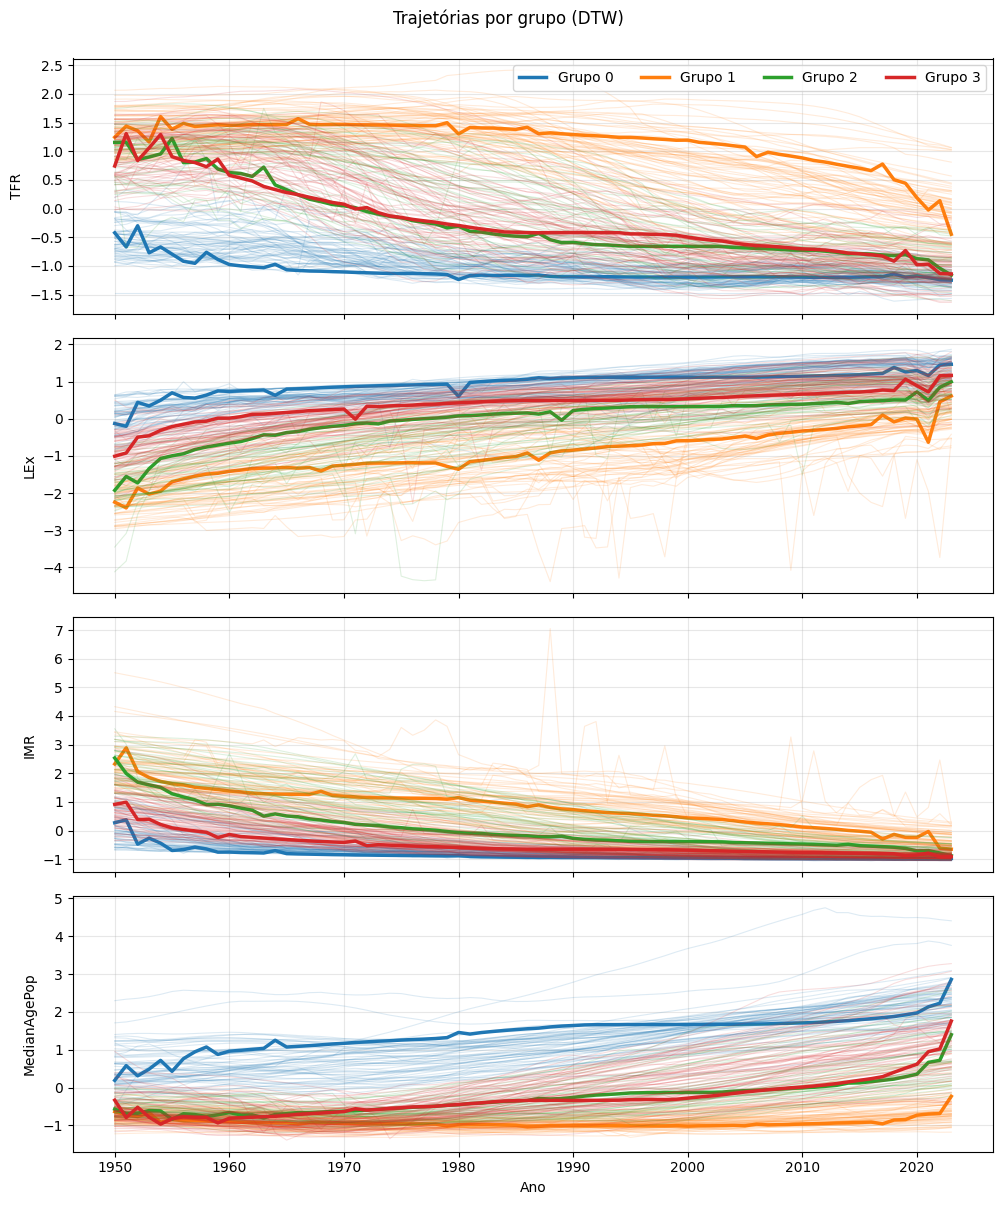

In [5]:
fig, eixos = plt.subplots(len(INDICADORES), 1, figsize=(10, 3 * len(INDICADORES)), sharex=True)
anos = np.arange(1950, 2024)
cores = plt.cm.tab10.colors

for i, ind in enumerate(INDICADORES):
    ax = eixos[i]
    for g in range(K):
        mascara = rotulos == g
        for serie in X[mascara]:
            ax.plot(anos, serie[:, i], color=cores[g], alpha=0.15, linewidth=0.8)
        ax.plot(anos, modelo.cluster_centers_[g][:, i], color=cores[g], linewidth=2.5, label=f"Grupo {g}")
    ax.set_ylabel(ind)
    ax.grid(alpha=0.3)

eixos[0].legend(loc="upper right", ncol=K)
eixos[-1].set_xlabel("Ano")
fig.suptitle("Trajetórias por grupo (DTW)", y=1.0)
fig.tight_layout()

SAIDA_FIG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(SAIDA_FIG, dpi=150, bbox_inches="tight")
plt.show()

## 6. Salvar o resultado

In [6]:
SAIDA_DADOS.parent.mkdir(parents=True, exist_ok=True)
clusters.to_csv(SAIDA_DADOS, index=False)
print(f"Salvo em {SAIDA_DADOS}")

Salvo em /Users/marcosabilio/Documents/GitHub/DataQuest2026/data/processed/clusters_dtw.csv


## Próximos passos

- Testar a estabilidade: rodar com outras sementes (`random_state`) e sem um dos indicadores, e ver se os países permanecem no mesmo grupo.
- Dar nomes aos grupos depois de interpretar as trajetórias.
- Comparar com o método vetorial (`matriz_vetor` + k-means), para checar se o DTW muda os grupos de forma relevante.